# Comparing plant segmentation methods

## Objective
Compare RGB K-means clustering with the blue-band and ExGVEG
threshold methods used in the MATLAB plant-area workflow.

## Methods
1. Blue-band threshold: B < 215.
2. ExGVEG threshold: ExGVEG > 1.05.
3. Combined threshold: blue-band AND ExGVEG criteria.
4. Cleaned combined threshold: remove connected components smaller
   than 20 pixels using 8-neighbor connectivity.
5. RGB K-means clustering, with clusters interpreted as plant
   or background after inspection.

## Fair comparison
Apply every method to the same original-resolution photograph
and the same polygon region of interest.

Inspect masks side by side, compare detected pixel counts, and
locate disagreements. Keep raw segmentation and cleanup results
separate so their effects can be distinguished.

## Evaluation
Differences in detected area and agreement between methods do
not establish accuracy.

Where manually checked reference masks are available, evaluate
false plant detections, missed plant tissue, precision, recall,
intersection over union, and projected-area error.

In [1]:
# File paths.
from pathlib import Path

# Arrays and data tables.
import numpy as np
import pandas as pd

# Image loading, plotting, and polygon cropping.
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.path import Path as PolygonPath

# Unsupervised classification.
from sklearn.cluster import KMeans

# Connected-component labeling for removing small objects.
from scipy import ndimage

In [2]:
# Project paths.
project_folder = Path(r"C:\Users\mguar\Documents\OEAS805\FinalProject")
raw_folder = project_folder / "DATA" / "raw"
image_folder = raw_folder / "GoProImages_Susquehanna_Milfoil"

# Load the data tables.
morphmeasures = pd.read_excel(
    raw_folder / "Morphmeasures_Susquehanna_milfoil.xlsx"
)
gopro_metadata = pd.read_excel(
    raw_folder / "GoPro_Metadata_Susquehanna_milfoil.xlsx"
)

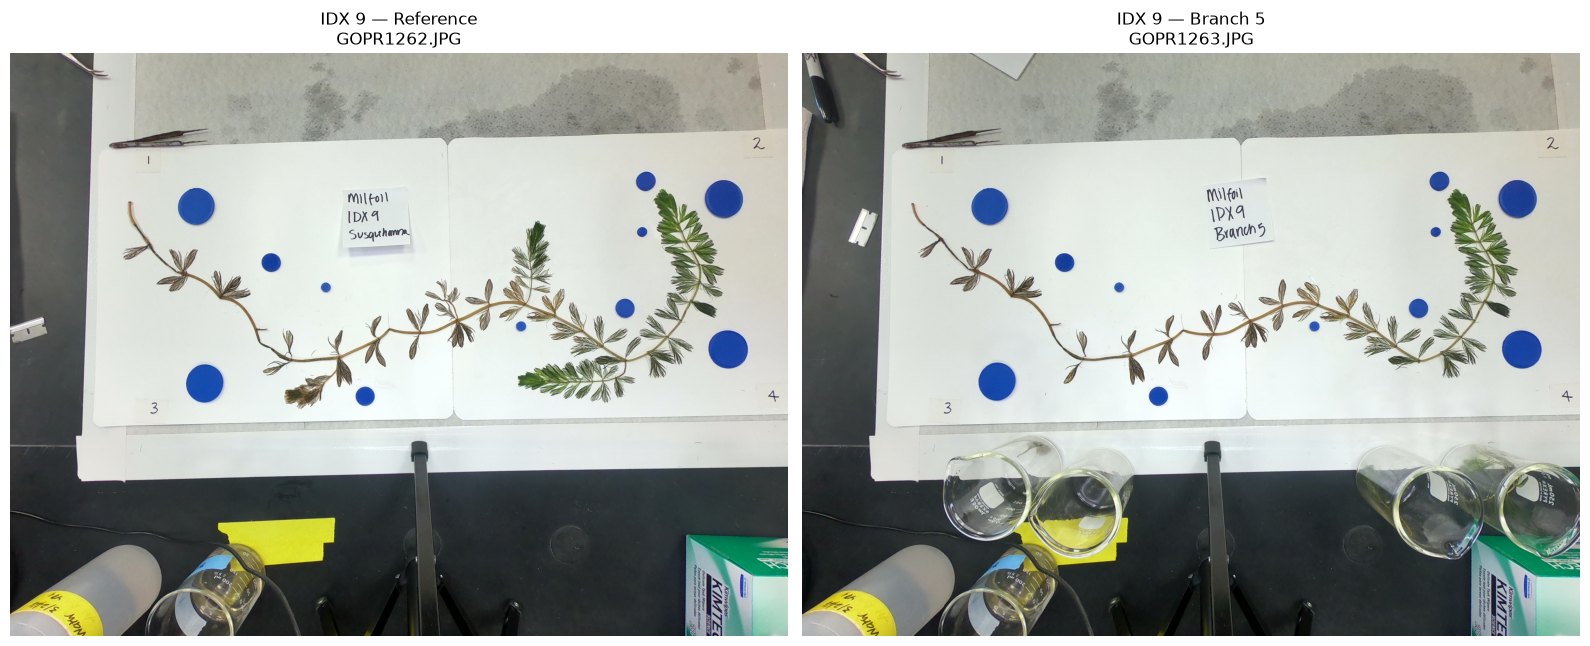

In [3]:
# Select the sample and branch.
idx = 9
branch_num = 5

matches = morphmeasures.loc[
    (morphmeasures["IDX"] == idx)
    & (morphmeasures["BRANCHNUM"] == branch_num)
]

if matches.empty:
    raise ValueError(f"No record found for IDX {idx}, Branch {branch_num}.")

row = matches.iloc[0]

# Match image names with or without file extensions.
image_lookup = {
    path.stem.upper(): path
    for path in image_folder.iterdir()
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
}

reference_path = image_lookup[
    Path(str(row["REFERENCE"]).strip()).stem.upper()
]
branch_path = image_lookup[
    Path(str(row["BRANCH"]).strip()).stem.upper()
]

# Load both images as RGB arrays.
with Image.open(reference_path) as img:
    reference_rgb = np.array(img.convert("RGB"))

with Image.open(branch_path) as img:
    branch_rgb = np.array(img.convert("RGB"))

# Display the photographs.
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(reference_rgb)
axes[0].set_title(f"IDX {idx} — Reference\n{reference_path.name}")

axes[1].imshow(branch_rgb)
axes[1].set_title(
    f"IDX {idx} — Branch {branch_num}\n{branch_path.name}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

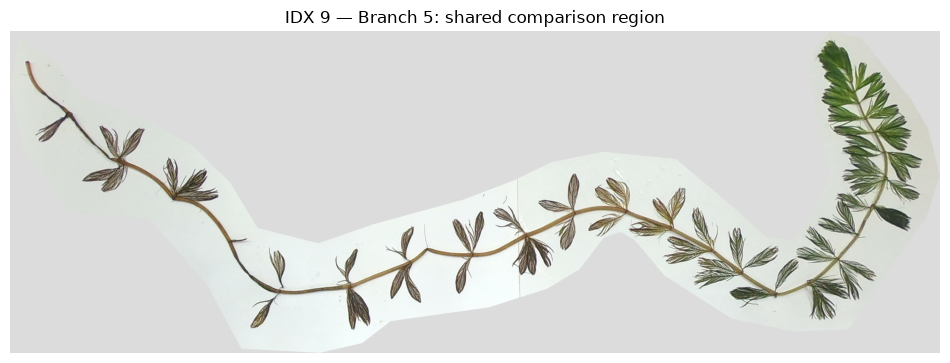

Pixels inside the polygon: 1,395,766


In [4]:
# Open an interactive window for polygon selection.
%matplotlib tk

fig, ax = plt.subplots(figsize=(14, 9))
ax.imshow(branch_rgb)
ax.set_title(
    f"IDX {idx} — Branch {branch_num}\n"
    "Click around the target branch — press Enter to finish"
)

crop_vertices = np.array(plt.ginput(n=-1, timeout=0))
plt.close(fig)

if len(crop_vertices) < 3:
    raise ValueError("Select at least three points to define the polygon.")

# Find the polygon's bounding rectangle.
height, width = branch_rgb.shape[:2]

x0 = max(0, int(np.floor(crop_vertices[:, 0].min())))
x1 = min(width, int(np.ceil(crop_vertices[:, 0].max())) + 1)
y0 = max(0, int(np.floor(crop_vertices[:, 1].min())))
y1 = min(height, int(np.ceil(crop_vertices[:, 1].max())) + 1)

if x1 <= x0 or y1 <= y0:
    raise ValueError("Select a region inside the image.")

# Crop without resizing: retain the original pixel values.
cropped_rgb = branch_rgb[y0:y1, x0:x1].copy()

# Shift polygon coordinates into the cropped image.
local_vertices = crop_vertices - np.array([x0, y0])
polygon = PolygonPath(local_vertices)

# Build the mask in row blocks to limit memory use.
crop_height, crop_width = cropped_rgb.shape[:2]
cropped_mask = np.zeros((crop_height, crop_width), dtype=bool)

block_rows = 256

for start in range(0, crop_height, block_rows):
    stop = min(start + block_rows, crop_height)

    yy, xx = np.mgrid[start:stop, 0:crop_width]
    points = np.column_stack([xx.ravel(), yy.ravel()])

    cropped_mask[start:stop] = polygon.contains_points(
        points
    ).reshape(stop - start, crop_width)

if not cropped_mask.any():
    raise ValueError("The selected polygon contains no image pixels.")

# Gray outside the polygon is for display only.
crop_preview = np.full_like(cropped_rgb, 220)
crop_preview[cropped_mask] = cropped_rgb[cropped_mask]

# Display the selected region inside the notebook.
%matplotlib inline

plt.figure(figsize=(12, 7))
plt.imshow(crop_preview)
plt.title(f"IDX {idx} — Branch {branch_num}: shared comparison region")
plt.axis("off")
plt.show()

print(f"Pixels inside the polygon: {cropped_mask.sum():,}")

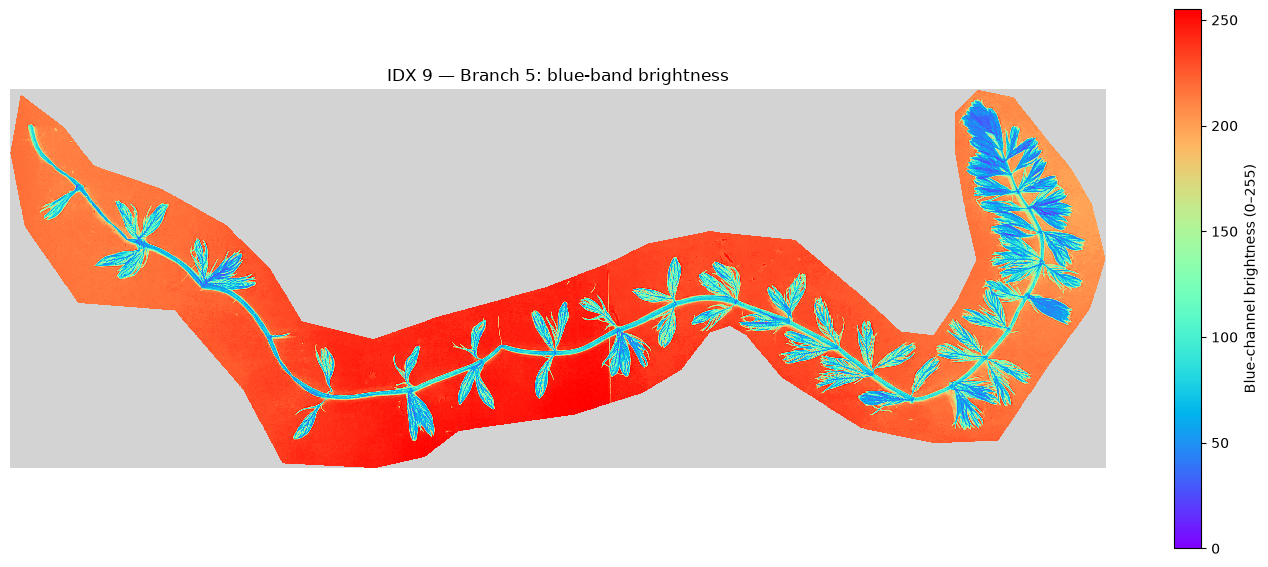

In [10]:
# Extract blue-channel brightness.
blue_band = cropped_rgb[..., 2]

# Hide pixels outside the polygon.
blue_display = np.ma.masked_where(~cropped_mask, blue_band)

# Use a rainbow color scale; gray outside the polygon.
blue_cmap = plt.get_cmap("rainbow").copy()
blue_cmap.set_bad("lightgray")

fig, ax = plt.subplots(figsize=(14, 8))

im = ax.imshow(
    blue_display,
    cmap=blue_cmap,
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

ax.set_title(f"IDX {idx} — Branch {branch_num}: blue-band brightness")
ax.axis("off")

fig.colorbar(
    im,
    ax=ax,
    label="Blue-channel brightness (0–255)",
    shrink=0.7
)

plt.tight_layout()
plt.show()

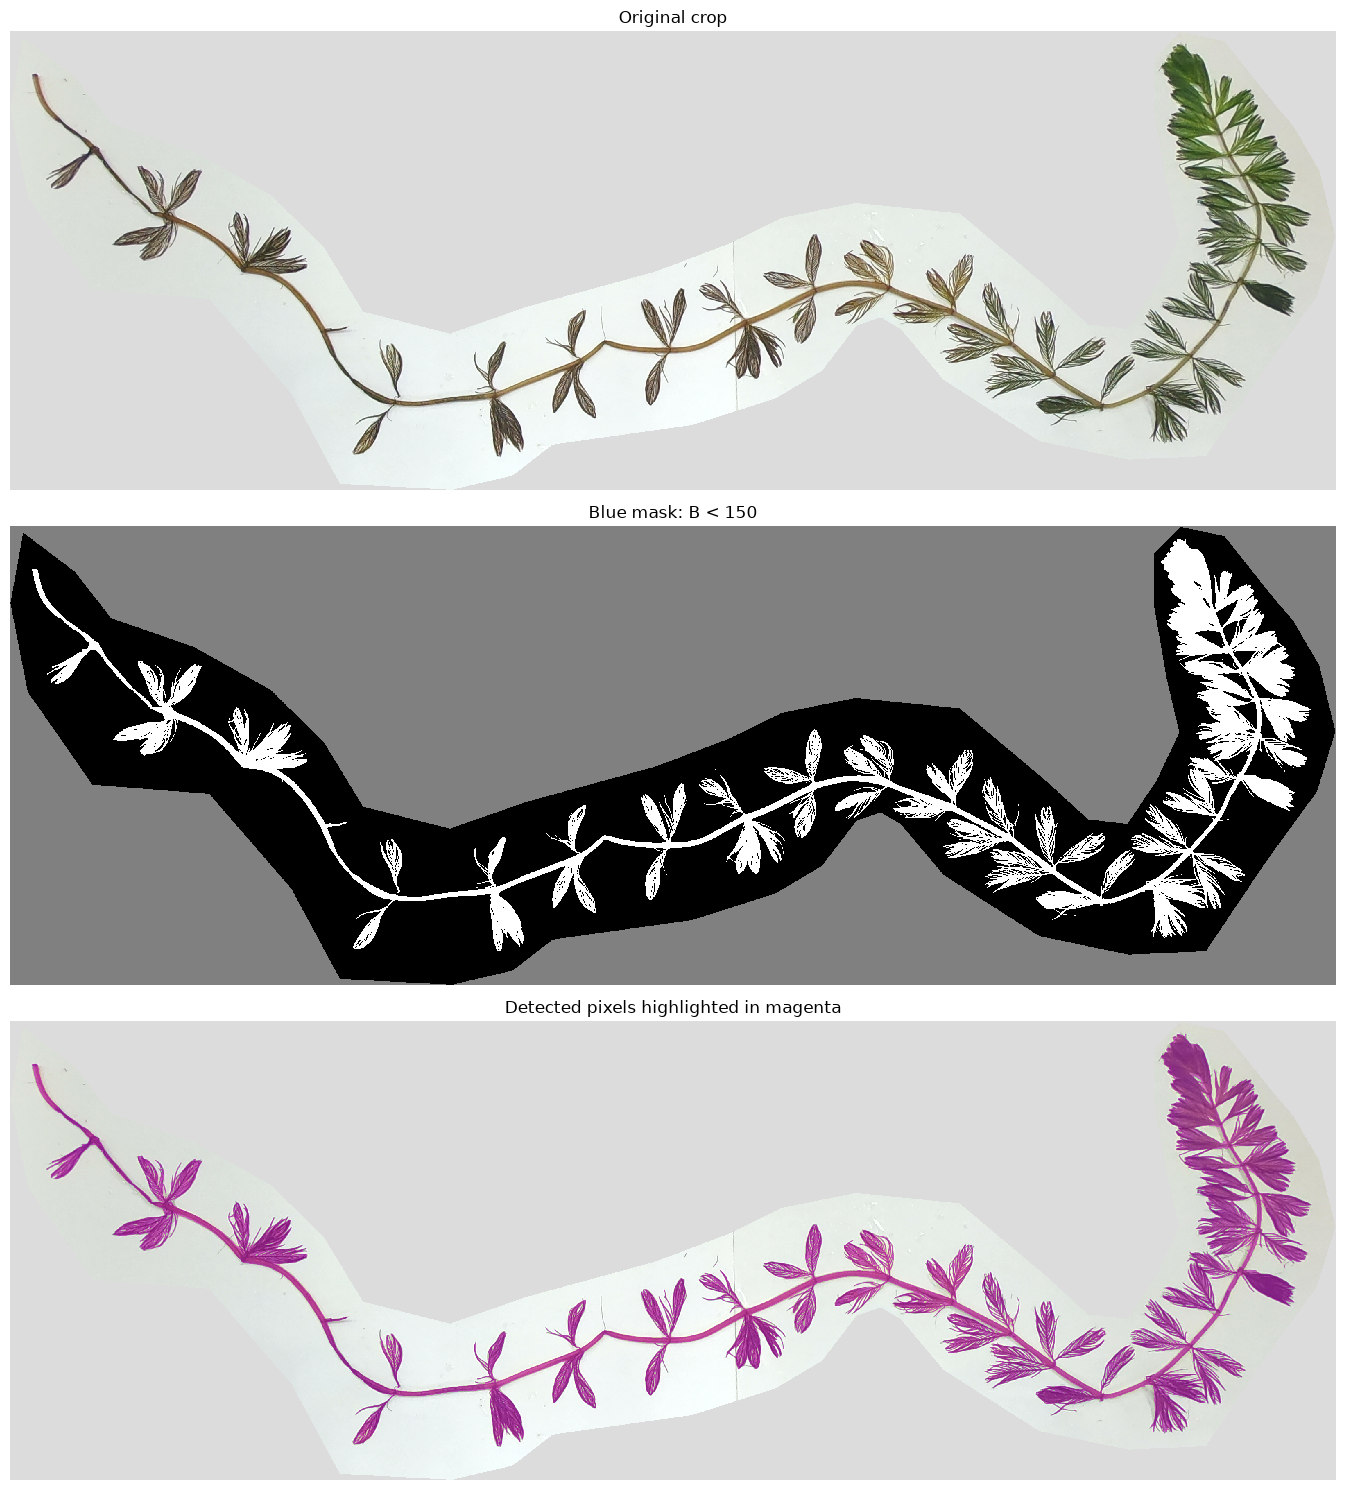

Included pixels: 294,784


In [11]:
# Test a blue-channel threshold.
blue_threshold = 150

# Include only pixels below the threshold and inside the polygon.
blue_band_mask = cropped_mask & (
    cropped_rgb[..., 2] < blue_threshold
)

# Mask display: gray outside, black rejected, white included.
mask_display = np.full(cropped_mask.shape, 0.5)
mask_display[cropped_mask] = blue_band_mask[cropped_mask].astype(float)

# Highlight included pixels in magenta over the original photograph.
overlay = crop_preview.astype(np.float64) / 255.0
overlay[blue_band_mask] = (
    0.6 * overlay[blue_band_mask]
    + 0.4 * np.array([1.0, 0.0, 1.0])
)

fig, axes = plt.subplots(3, 1, figsize=(16, 15))

axes[0].imshow(crop_preview, interpolation="nearest")
axes[0].set_title("Original crop")

axes[1].imshow(
    mask_display,
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)
axes[1].set_title(f"Blue mask: B < {blue_threshold}")

axes[2].imshow(overlay, interpolation="nearest")
axes[2].set_title("Detected pixels highlighted in magenta")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Included pixels: {blue_band_mask.sum():,}")

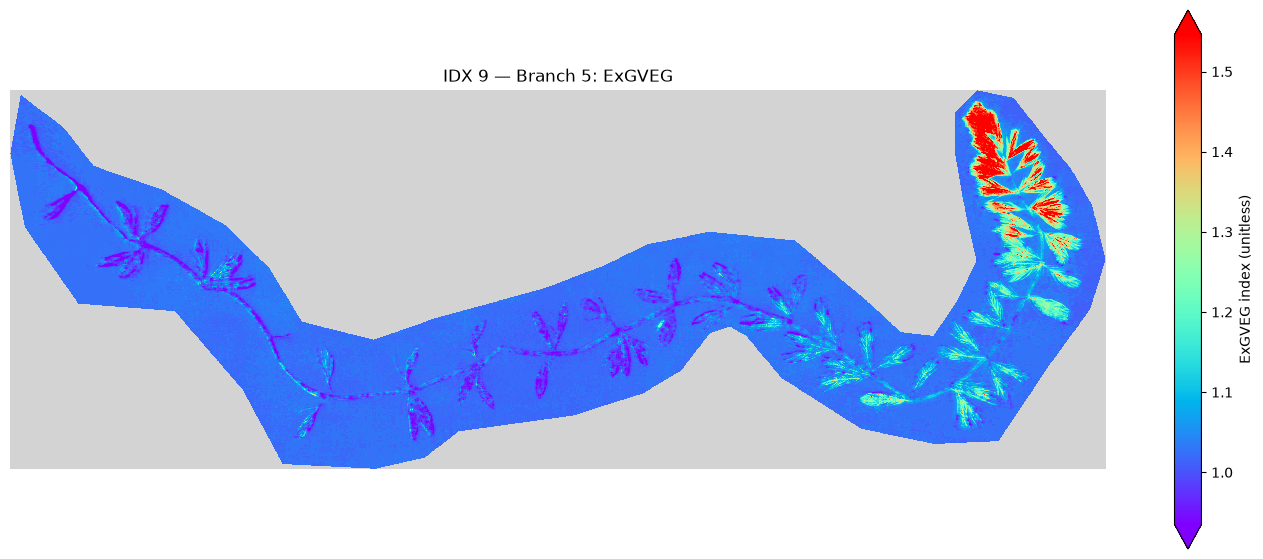

In [13]:
# Extract RGB channels as double precision.
rgb = cropped_rgb.astype(np.float64)
r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]

# Normalize RGB.
eps = np.finfo(np.float64).eps
rgb_sum = r + g + b + eps

r_norm = r / rgb_sum
g_norm = g / rgb_sum
b_norm = b / rgb_sum

# Calculate ExGVEG using the formula from your MATLAB script.
exgveg = g_norm / (
    (r_norm ** 0.667) * (b_norm ** (1 - 0.667)) + eps
)

# Hide pixels outside the polygon.
exgveg_display = np.ma.masked_where(~cropped_mask, exgveg)

# Rainbow color scale; gray outside the polygon.
exgveg_cmap = plt.get_cmap("rainbow").copy()
exgveg_cmap.set_bad("lightgray")

# Set display limits from values inside the polygon.
# Percentiles reduce the influence of extreme values on the color scale.
vmin, vmax = np.percentile(exgveg[cropped_mask], [1, 99])

fig, ax = plt.subplots(figsize=(14, 8))

im = ax.imshow(
    exgveg_display,
    cmap=exgveg_cmap,
    vmin=vmin,
    vmax=vmax,
    interpolation="nearest"
)

ax.set_title(f"IDX {idx} — Branch {branch_num}: ExGVEG")
ax.axis("off")

fig.colorbar(
    im,
    ax=ax,
    label="ExGVEG index (unitless)",
    shrink=0.7,
    extend="both"
)

plt.tight_layout()
plt.show()

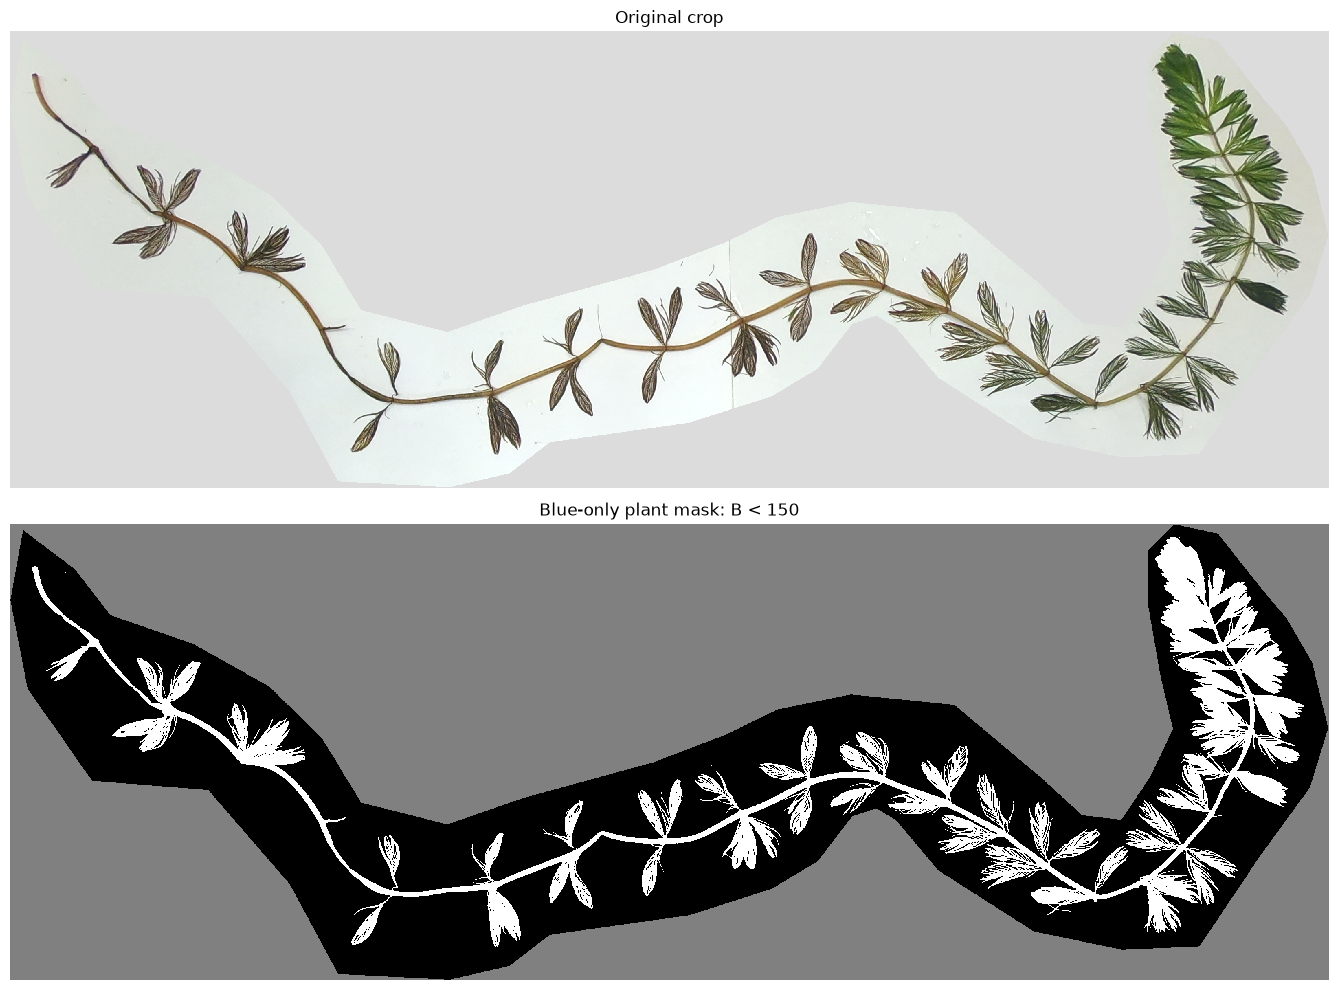

Detected pixels: 294,784


In [14]:
# Blue threshold selected from your visual inspection.
blue_threshold = 150

# Identify candidate plant pixels inside the polygon.
blue_band_mask = cropped_mask & (
    cropped_rgb[..., 2] < blue_threshold
)

# Use this as the threshold-based plant mask for later comparisons.
plant_mask = blue_band_mask.copy()

# Display: gray outside polygon, white included, black excluded.
mask_display = np.full(cropped_mask.shape, 0.5)
mask_display[cropped_mask] = plant_mask[cropped_mask].astype(float)

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

axes[0].imshow(crop_preview, interpolation="nearest")
axes[0].set_title("Original crop")

axes[1].imshow(
    mask_display,
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)
axes[1].set_title(f"Blue-only plant mask: B < {blue_threshold}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Detected pixels: {plant_mask.sum():,}")

In [15]:
# Match the selected branch image to its metadata.
metadata_image_names = gopro_metadata["GOPROFILE"].map(
    lambda name: Path(str(name).strip()).stem.upper()
)

metadata_match = gopro_metadata.loc[
    metadata_image_names == branch_path.stem.upper()
]

if len(metadata_match) != 1:
    raise ValueError(
        f"Expected one metadata record for {branch_path.name}; "
        f"found {len(metadata_match)}."
    )

# Retrieve the image-specific area calibration.
pixel_area_cm2 = float(
    metadata_match.iloc[0]["MeanPixelArea_cm2PerPixel2"]
)

if not np.isfinite(pixel_area_cm2) or pixel_area_cm2 <= 0:
    raise ValueError(f"Invalid pixel-area calibration: {pixel_area_cm2}")

# Recalculate the blue mask using the currently selected threshold.
blue_band_mask = cropped_mask & (
    cropped_rgb[..., 2] < blue_threshold
)

# Convert included pixel count to projected area.
blue_plant_pixels = int(blue_band_mask.sum())
blue_plant_area_cm2 = blue_plant_pixels * pixel_area_cm2

# Summarize the estimate.
blue_area_summary = pd.DataFrame([{
    "IDX": idx,
    "Branch": branch_num,
    "Image": branch_path.name,
    "Blue_threshold": blue_threshold,
    "Plant_pixels": blue_plant_pixels,
    "Pixel_area_cm2": pixel_area_cm2,
    "Projected_area_cm2": blue_plant_area_cm2,
}])

display(blue_area_summary)

print(f"Blue-only projected plant area: {blue_plant_area_cm2:.4f} cm²")

,IDX,Branch,Image,Blue_threshold,Plant_pixels,Pixel_area_cm2,Projected_area_cm2
0,9,5,GOPR1263.JPG,150,294784,0.000502,147.988842


Blue-only projected plant area: 147.9888 cm²


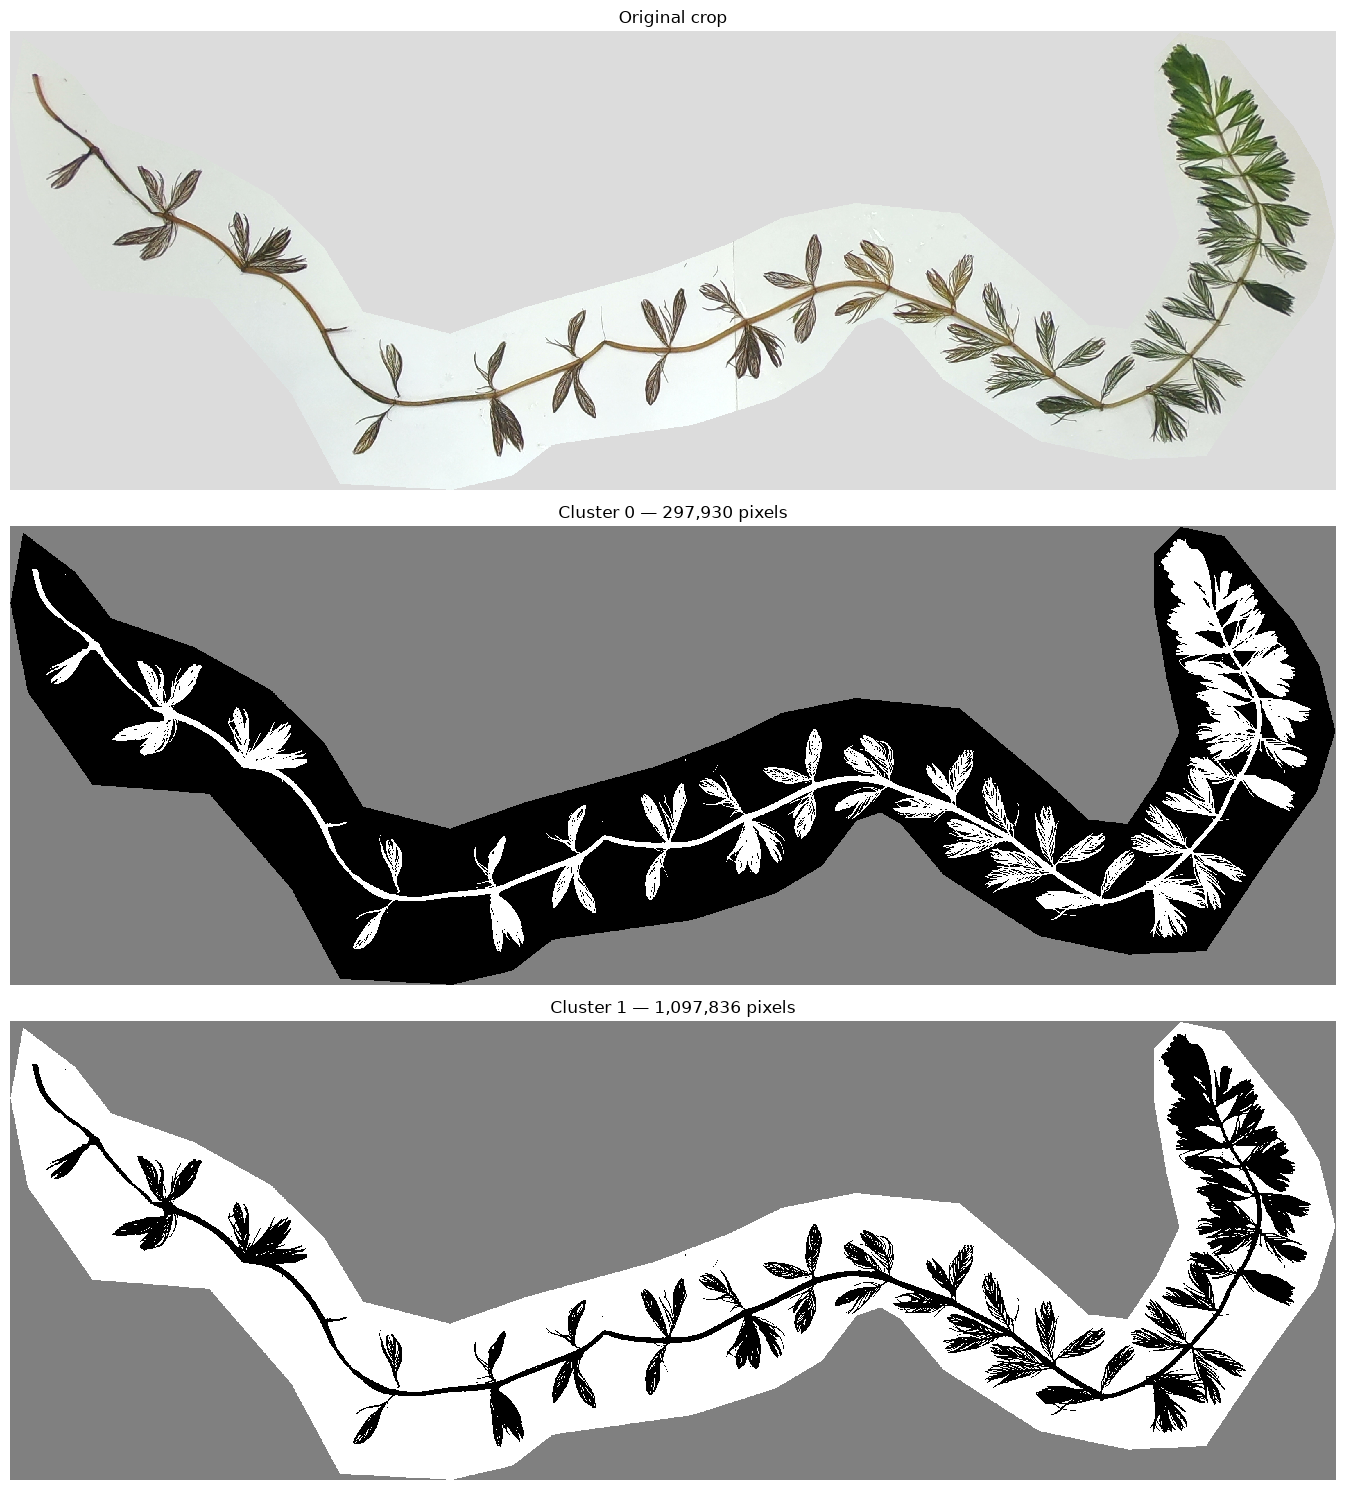

In [16]:
# Use RGB values from pixels inside the shared polygon.
k = 2
pixels = cropped_rgb[cropped_mask].astype(np.float32) / 255.0

# Fit on a reproducible random sample for speed.
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(pixels),
    size=min(50_000, len(pixels)),
    replace=False
)

kmeans_model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)
kmeans_model.fit(pixels[sample_indices])

# Predict every pixel inside the polygon at original resolution.
kmeans_map = np.full(cropped_mask.shape, -1, dtype=int)
kmeans_map[cropped_mask] = kmeans_model.predict(pixels)

# Display the original crop and each cluster separately.
fig, axes = plt.subplots(k + 1, 1, figsize=(16, 15))

axes[0].imshow(crop_preview, interpolation="nearest")
axes[0].set_title("Original crop")

for cluster_id in range(k):
    cluster_mask = kmeans_map == cluster_id

    # Gray outside polygon; white belongs to this cluster.
    display_mask = np.full(cropped_mask.shape, 0.5)
    display_mask[cropped_mask] = (
        cluster_mask[cropped_mask].astype(float)
    )

    axes[cluster_id + 1].imshow(
        display_mask,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    axes[cluster_id + 1].set_title(
        f"Cluster {cluster_id} — {cluster_mask.sum():,} pixels"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Select the plant cluster based on visual inspection.
plant_cluster_id = 0

kmeans_plant_mask = cropped_mask & (
    kmeans_map == plant_cluster_id
)

# Convert pixel count to area using the same image calibration.
kmeans_plant_pixels = int(kmeans_plant_mask.sum())
kmeans_plant_area_cm2 = kmeans_plant_pixels * pixel_area_cm2

# Compare both methods.
area_comparison = pd.DataFrame([
    {
        "Method": f"Blue threshold < {blue_threshold:g}",
        "Plant_pixels": blue_plant_pixels,
        "Projected_area_cm2": blue_plant_area_cm2,
    },
    {
        "Method": f"RGB K-means — cluster {plant_cluster_id}",
        "Plant_pixels": kmeans_plant_pixels,
        "Projected_area_cm2": kmeans_plant_area_cm2,
    },
])

display(area_comparison)

print(
    "Area difference (K-means − blue): "
    f"{kmeans_plant_area_cm2 - blue_plant_area_cm2:.4f} cm²"
)

,Method,Plant_pixels,Projected_area_cm2
0,Blue threshold < 150,294784,147.988842
1,RGB K-means — cluster 0,297930,149.568212


Area difference (K-means − blue): 1.5794 cm²


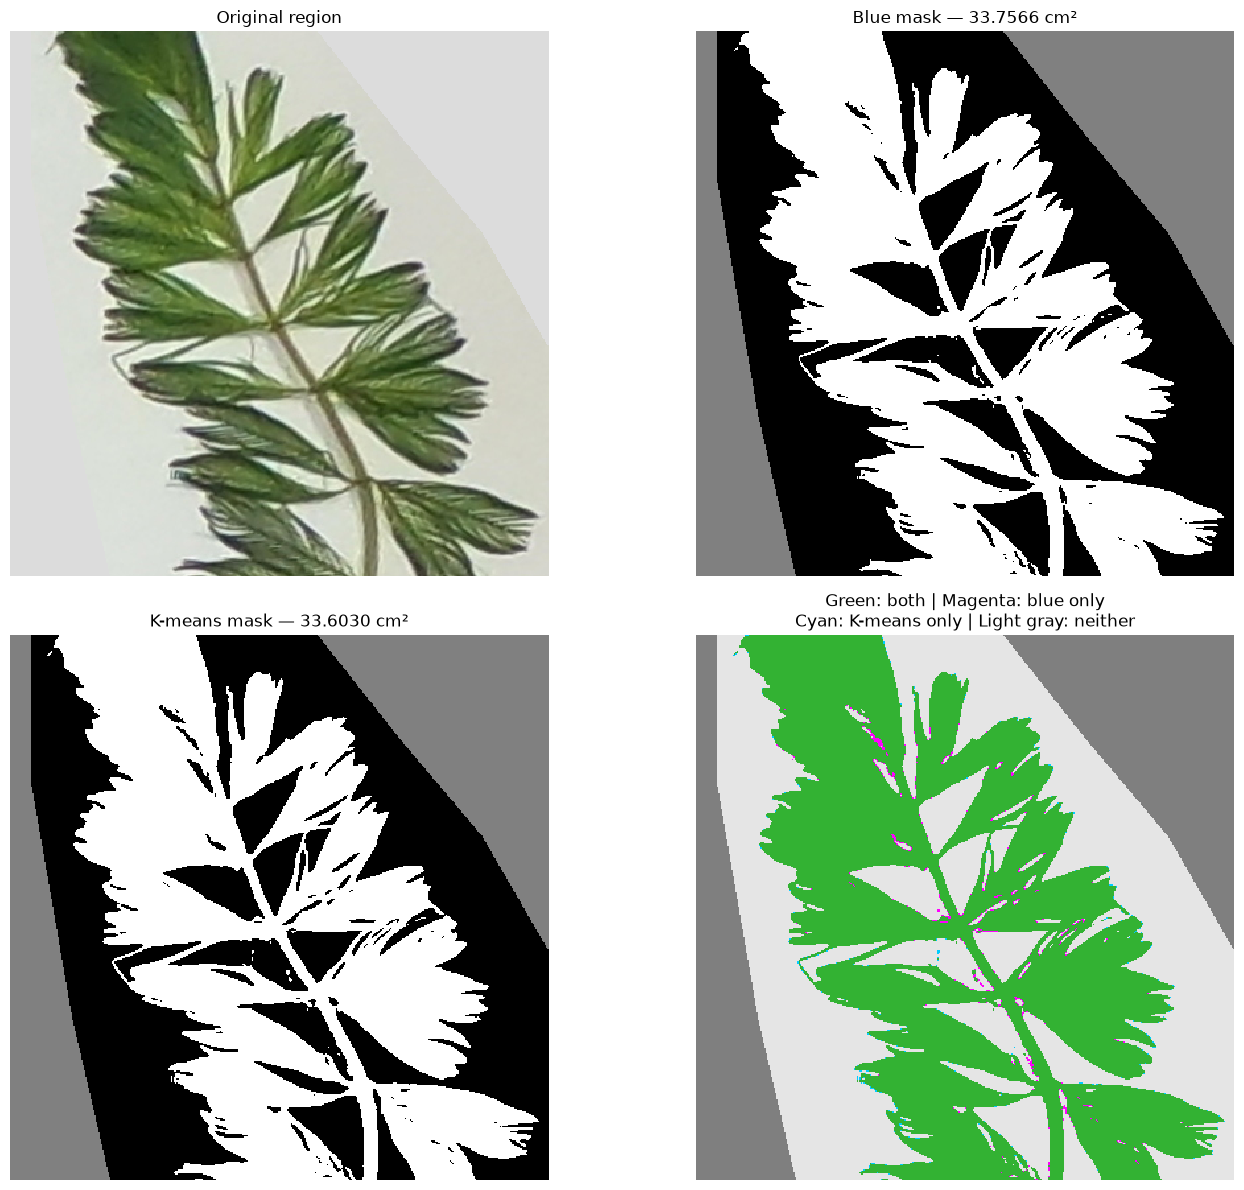

,Method,Detected_pixels,Projected_area_cm2
0,Blue < 150,67241,33.756641
1,RGB K-means,66935,33.603022


Area difference (K-means − blue): -0.1536 cm²
Blue-only pixels:   649
K-means-only pixels: 343


In [18]:
# Select a smaller region for comparison.
%matplotlib tk

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(crop_preview)
ax.set_title(
    "Click TWO opposite corners around the region to compare"
)

corners = np.array(plt.ginput(n=2, timeout=0))
plt.close(fig)

if len(corners) != 2:
    raise ValueError("Select two opposite corners.")

# Rectangle coordinates within the existing crop.
h, w = cropped_rgb.shape[:2]

zx0 = max(0, int(np.floor(corners[:, 0].min())))
zx1 = min(w, int(np.ceil(corners[:, 0].max())) + 1)
zy0 = max(0, int(np.floor(corners[:, 1].min())))
zy1 = min(h, int(np.ceil(corners[:, 1].max())) + 1)

if zx1 <= zx0 or zy1 <= zy0:
    raise ValueError("Select a rectangle inside the image.")

region = np.s_[zy0:zy1, zx0:zx1]

# Retain the original polygon restriction.
local_roi = cropped_mask[region]
local_rgb = crop_preview[region]
local_blue = blue_band_mask[region] & local_roi
local_kmeans = kmeans_plant_mask[region] & local_roi

if not local_roi.any():
    raise ValueError("This rectangle contains no pixels inside the polygon.")

# Calculate area for each mask within this rectangle.
local_summary = pd.DataFrame([
    {
        "Method": f"Blue < {blue_threshold:g}",
        "Detected_pixels": int(local_blue.sum()),
        "Projected_area_cm2": local_blue.sum() * pixel_area_cm2,
    },
    {
        "Method": "RGB K-means",
        "Detected_pixels": int(local_kmeans.sum()),
        "Projected_area_cm2": local_kmeans.sum() * pixel_area_cm2,
    },
])

# Disagreement colors:
# light gray = neither; green = both;
# magenta = blue only; cyan = K-means only.
agreement_rgb = np.full((*local_roi.shape, 3), 0.9)
agreement_rgb[~local_roi] = [0.5, 0.5, 0.5]

both = local_blue & local_kmeans
blue_only = local_blue & ~local_kmeans
kmeans_only = local_kmeans & ~local_blue

agreement_rgb[both] = [0.2, 0.7, 0.2]
agreement_rgb[blue_only] = [1.0, 0.0, 1.0]
agreement_rgb[kmeans_only] = [0.0, 0.8, 1.0]

%matplotlib inline

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

axes[0, 0].imshow(local_rgb, interpolation="nearest")
axes[0, 0].set_title("Original region")

for ax, mask, title in [
    (
        axes[0, 1],
        local_blue,
        f"Blue mask — {local_blue.sum() * pixel_area_cm2:.4f} cm²"
    ),
    (
        axes[1, 0],
        local_kmeans,
        f"K-means mask — {local_kmeans.sum() * pixel_area_cm2:.4f} cm²"
    ),
]:
    display_mask = np.full(local_roi.shape, 0.5)
    display_mask[local_roi] = mask[local_roi].astype(float)

    ax.imshow(
        display_mask,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    ax.set_title(title)

axes[1, 1].imshow(agreement_rgb, interpolation="nearest")
axes[1, 1].set_title(
    "Green: both | Magenta: blue only\n"
    "Cyan: K-means only | Light gray: neither"
)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

display(local_summary)

print(
    "Area difference (K-means − blue): "
    f"{(local_kmeans.sum() - local_blue.sum()) * pixel_area_cm2:.4f} cm²"
)
print(f"Blue-only pixels:   {blue_only.sum():,}")
print(f"K-means-only pixels: {kmeans_only.sum():,}")

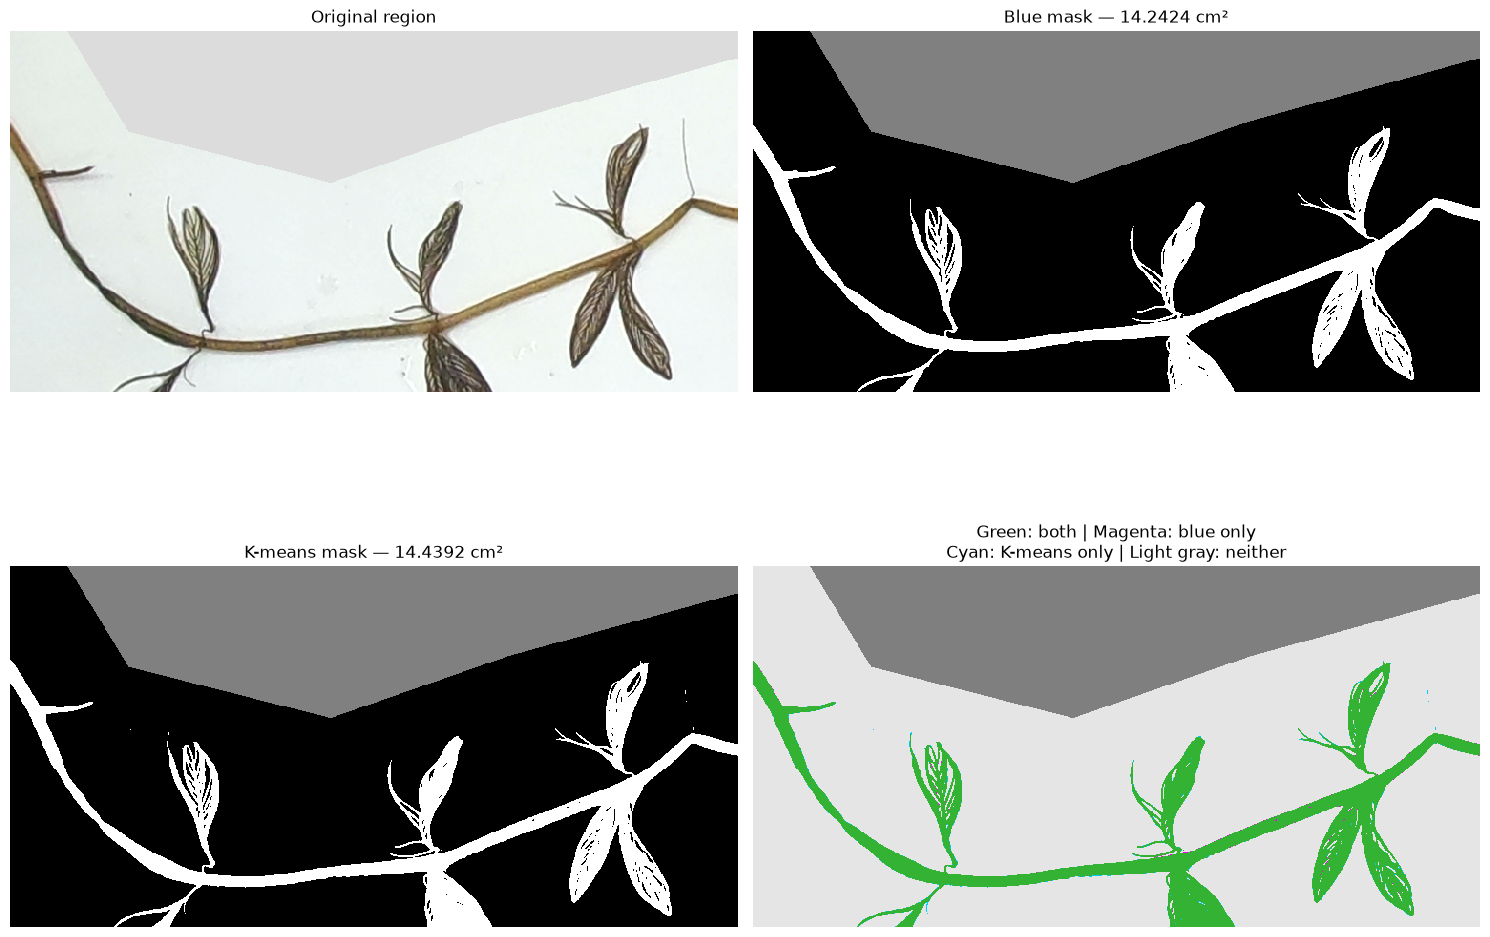

,Method,Detected_pixels,Projected_area_cm2
0,Blue < 150,28370,14.242440
1,RGB K-means,28762,14.439234


Area difference (K-means − blue): 0.1968 cm²
Blue-only pixels:   111
K-means-only pixels: 503


In [19]:
# Select a smaller region for comparison.
%matplotlib tk

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(crop_preview)
ax.set_title(
    "Click TWO opposite corners around the region to compare"
)

corners = np.array(plt.ginput(n=2, timeout=0))
plt.close(fig)

if len(corners) != 2:
    raise ValueError("Select two opposite corners.")

# Rectangle coordinates within the existing crop.
h, w = cropped_rgb.shape[:2]

zx0 = max(0, int(np.floor(corners[:, 0].min())))
zx1 = min(w, int(np.ceil(corners[:, 0].max())) + 1)
zy0 = max(0, int(np.floor(corners[:, 1].min())))
zy1 = min(h, int(np.ceil(corners[:, 1].max())) + 1)

if zx1 <= zx0 or zy1 <= zy0:
    raise ValueError("Select a rectangle inside the image.")

region = np.s_[zy0:zy1, zx0:zx1]

# Retain the original polygon restriction.
local_roi = cropped_mask[region]
local_rgb = crop_preview[region]
local_blue = blue_band_mask[region] & local_roi
local_kmeans = kmeans_plant_mask[region] & local_roi

if not local_roi.any():
    raise ValueError("This rectangle contains no pixels inside the polygon.")

# Calculate area for each mask within this rectangle.
local_summary = pd.DataFrame([
    {
        "Method": f"Blue < {blue_threshold:g}",
        "Detected_pixels": int(local_blue.sum()),
        "Projected_area_cm2": local_blue.sum() * pixel_area_cm2,
    },
    {
        "Method": "RGB K-means",
        "Detected_pixels": int(local_kmeans.sum()),
        "Projected_area_cm2": local_kmeans.sum() * pixel_area_cm2,
    },
])

# Disagreement colors:
# light gray = neither; green = both;
# magenta = blue only; cyan = K-means only.
agreement_rgb = np.full((*local_roi.shape, 3), 0.9)
agreement_rgb[~local_roi] = [0.5, 0.5, 0.5]

both = local_blue & local_kmeans
blue_only = local_blue & ~local_kmeans
kmeans_only = local_kmeans & ~local_blue

agreement_rgb[both] = [0.2, 0.7, 0.2]
agreement_rgb[blue_only] = [1.0, 0.0, 1.0]
agreement_rgb[kmeans_only] = [0.0, 0.8, 1.0]

%matplotlib inline

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

axes[0, 0].imshow(local_rgb, interpolation="nearest")
axes[0, 0].set_title("Original region")

for ax, mask, title in [
    (
        axes[0, 1],
        local_blue,
        f"Blue mask — {local_blue.sum() * pixel_area_cm2:.4f} cm²"
    ),
    (
        axes[1, 0],
        local_kmeans,
        f"K-means mask — {local_kmeans.sum() * pixel_area_cm2:.4f} cm²"
    ),
]:
    display_mask = np.full(local_roi.shape, 0.5)
    display_mask[local_roi] = mask[local_roi].astype(float)

    ax.imshow(
        display_mask,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    ax.set_title(title)

axes[1, 1].imshow(agreement_rgb, interpolation="nearest")
axes[1, 1].set_title(
    "Green: both | Magenta: blue only\n"
    "Cyan: K-means only | Light gray: neither"
)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

display(local_summary)

print(
    "Area difference (K-means − blue): "
    f"{(local_kmeans.sum() - local_blue.sum()) * pixel_area_cm2:.4f} cm²"
)
print(f"Blue-only pixels:   {blue_only.sum():,}")
print(f"K-means-only pixels: {kmeans_only.sum():,}")

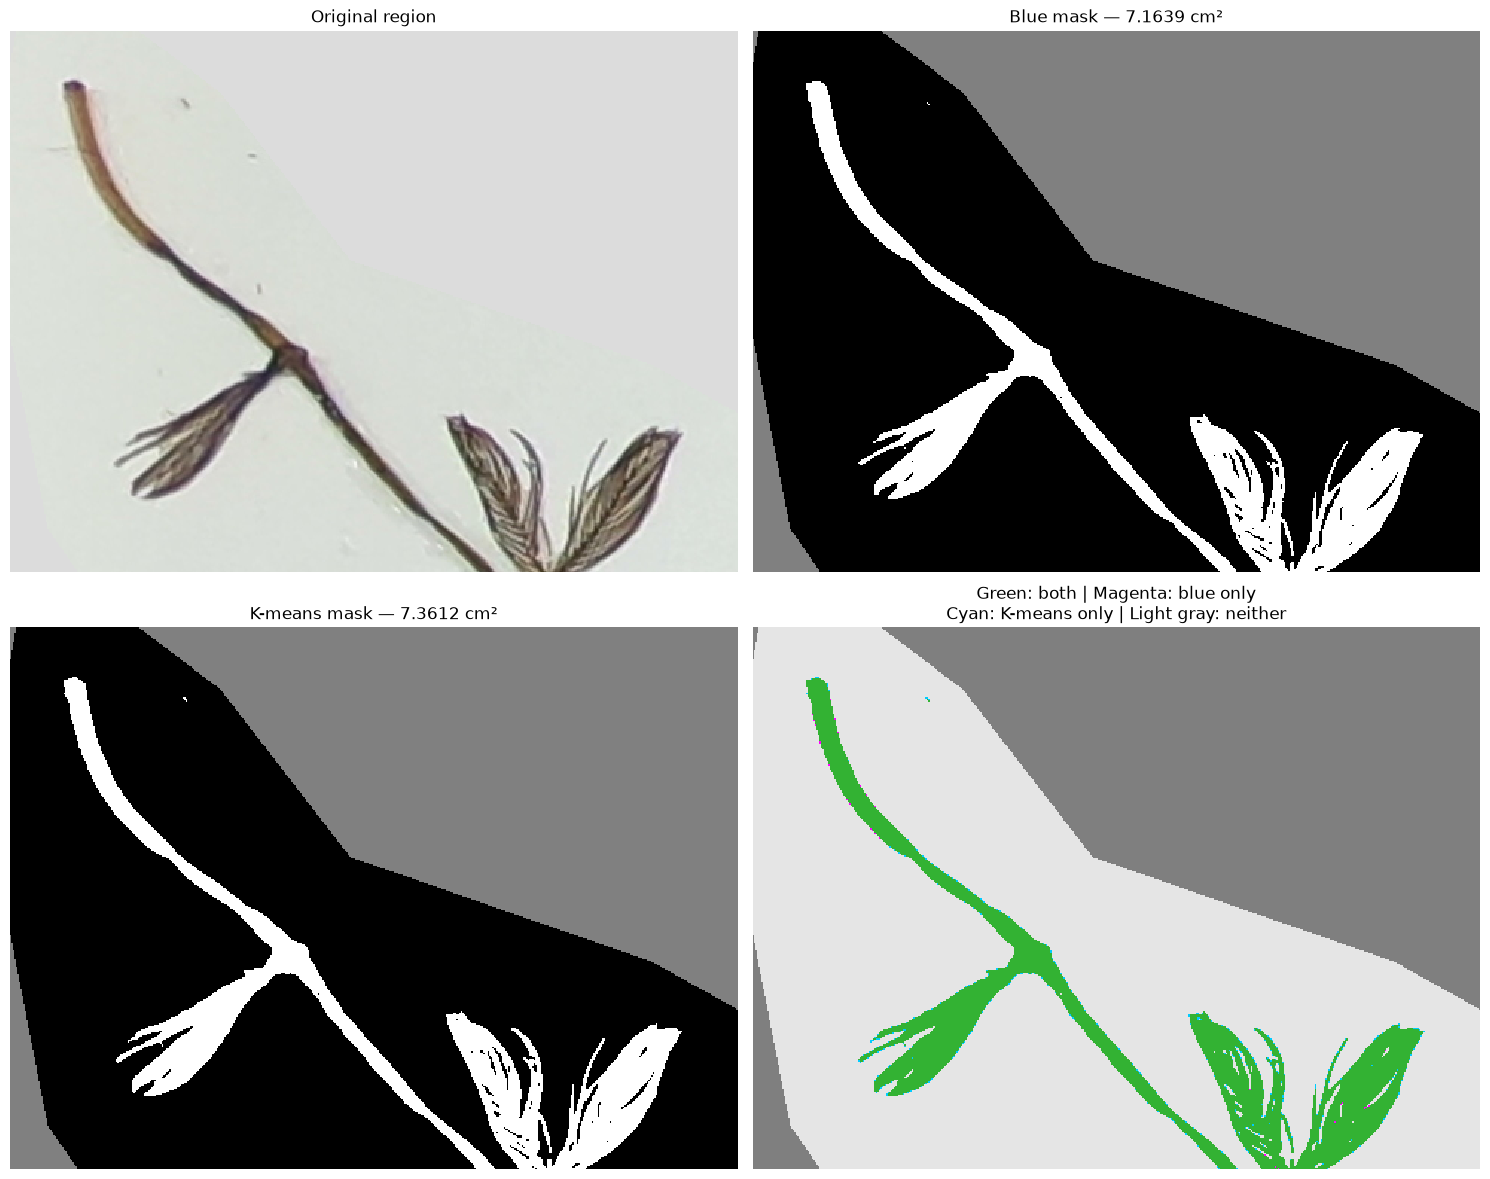

,Method,Detected_pixels,Projected_area_cm2
0,Blue < 150,14270,7.163892
1,RGB K-means,14663,7.361188


Area difference (K-means − blue): 0.1973 cm²
Blue-only pixels:   30
K-means-only pixels: 423


In [20]:
# Select a smaller region for comparison.
%matplotlib tk

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(crop_preview)
ax.set_title(
    "Click TWO opposite corners around the region to compare"
)

corners = np.array(plt.ginput(n=2, timeout=0))
plt.close(fig)

if len(corners) != 2:
    raise ValueError("Select two opposite corners.")

# Rectangle coordinates within the existing crop.
h, w = cropped_rgb.shape[:2]

zx0 = max(0, int(np.floor(corners[:, 0].min())))
zx1 = min(w, int(np.ceil(corners[:, 0].max())) + 1)
zy0 = max(0, int(np.floor(corners[:, 1].min())))
zy1 = min(h, int(np.ceil(corners[:, 1].max())) + 1)

if zx1 <= zx0 or zy1 <= zy0:
    raise ValueError("Select a rectangle inside the image.")

region = np.s_[zy0:zy1, zx0:zx1]

# Retain the original polygon restriction.
local_roi = cropped_mask[region]
local_rgb = crop_preview[region]
local_blue = blue_band_mask[region] & local_roi
local_kmeans = kmeans_plant_mask[region] & local_roi

if not local_roi.any():
    raise ValueError("This rectangle contains no pixels inside the polygon.")

# Calculate area for each mask within this rectangle.
local_summary = pd.DataFrame([
    {
        "Method": f"Blue < {blue_threshold:g}",
        "Detected_pixels": int(local_blue.sum()),
        "Projected_area_cm2": local_blue.sum() * pixel_area_cm2,
    },
    {
        "Method": "RGB K-means",
        "Detected_pixels": int(local_kmeans.sum()),
        "Projected_area_cm2": local_kmeans.sum() * pixel_area_cm2,
    },
])

# Disagreement colors:
# light gray = neither; green = both;
# magenta = blue only; cyan = K-means only.
agreement_rgb = np.full((*local_roi.shape, 3), 0.9)
agreement_rgb[~local_roi] = [0.5, 0.5, 0.5]

both = local_blue & local_kmeans
blue_only = local_blue & ~local_kmeans
kmeans_only = local_kmeans & ~local_blue

agreement_rgb[both] = [0.2, 0.7, 0.2]
agreement_rgb[blue_only] = [1.0, 0.0, 1.0]
agreement_rgb[kmeans_only] = [0.0, 0.8, 1.0]

%matplotlib inline

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

axes[0, 0].imshow(local_rgb, interpolation="nearest")
axes[0, 0].set_title("Original region")

for ax, mask, title in [
    (
        axes[0, 1],
        local_blue,
        f"Blue mask — {local_blue.sum() * pixel_area_cm2:.4f} cm²"
    ),
    (
        axes[1, 0],
        local_kmeans,
        f"K-means mask — {local_kmeans.sum() * pixel_area_cm2:.4f} cm²"
    ),
]:
    display_mask = np.full(local_roi.shape, 0.5)
    display_mask[local_roi] = mask[local_roi].astype(float)

    ax.imshow(
        display_mask,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    ax.set_title(title)

axes[1, 1].imshow(agreement_rgb, interpolation="nearest")
axes[1, 1].set_title(
    "Green: both | Magenta: blue only\n"
    "Cyan: K-means only | Light gray: neither"
)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

display(local_summary)

print(
    "Area difference (K-means − blue): "
    f"{(local_kmeans.sum() - local_blue.sum()) * pixel_area_cm2:.4f} cm²"
)
print(f"Blue-only pixels:   {blue_only.sum():,}")
print(f"K-means-only pixels: {kmeans_only.sum():,}")